# Iris Flower Classification
**Oasis Infobyte SIP — Data Science Track — Task 1**

**Objective:** Train a machine learning classification model to identify the species of an iris flower
(*Setosa*, *Versicolor*, or *Virginica*) from its physical measurements (sepal length, sepal width,
petal length, petal width).

**Author:** Himanshee
**Tech Stack:** Python, scikit-learn, pandas, matplotlib, seaborn


## 1. Imports and Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

sns.set_style("whitegrid")
%matplotlib inline

## 2. Load the Dataset

The Iris dataset ships directly with scikit-learn, so no external download is required.
It contains 150 samples, 50 for each of 3 species, with 4 numeric features each.

In [2]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = pd.Categorical.from_codes(iris.target, iris.target_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Exploratory Data Analysis (EDA)

Before modelling, check the shape, data types, missing values, and summary statistics
of the dataset.

In [3]:
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())

Shape: (150, 5)

Data types:
 sepal length (cm)     float64
sepal width (cm)      float64
petal length (cm)     float64
petal width (cm)      float64
species              category
dtype: object

Missing values:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


In [4]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


**Observations:**
- The dataset is perfectly balanced (50 samples per species) and has **zero missing values**,
  so no cleaning or imputation is required.
- All four features are continuous numeric measurements in centimetres.
- Petal measurements (length and width) show a much larger spread (std) relative to their mean
  than sepal measurements, which is an early hint that they vary more across species and could
  be more discriminative.

## 4. Visualisations

### 4.1 Pairplot — feature distributions by species
A pairplot shows every pair of features against each other, colour-coded by species.

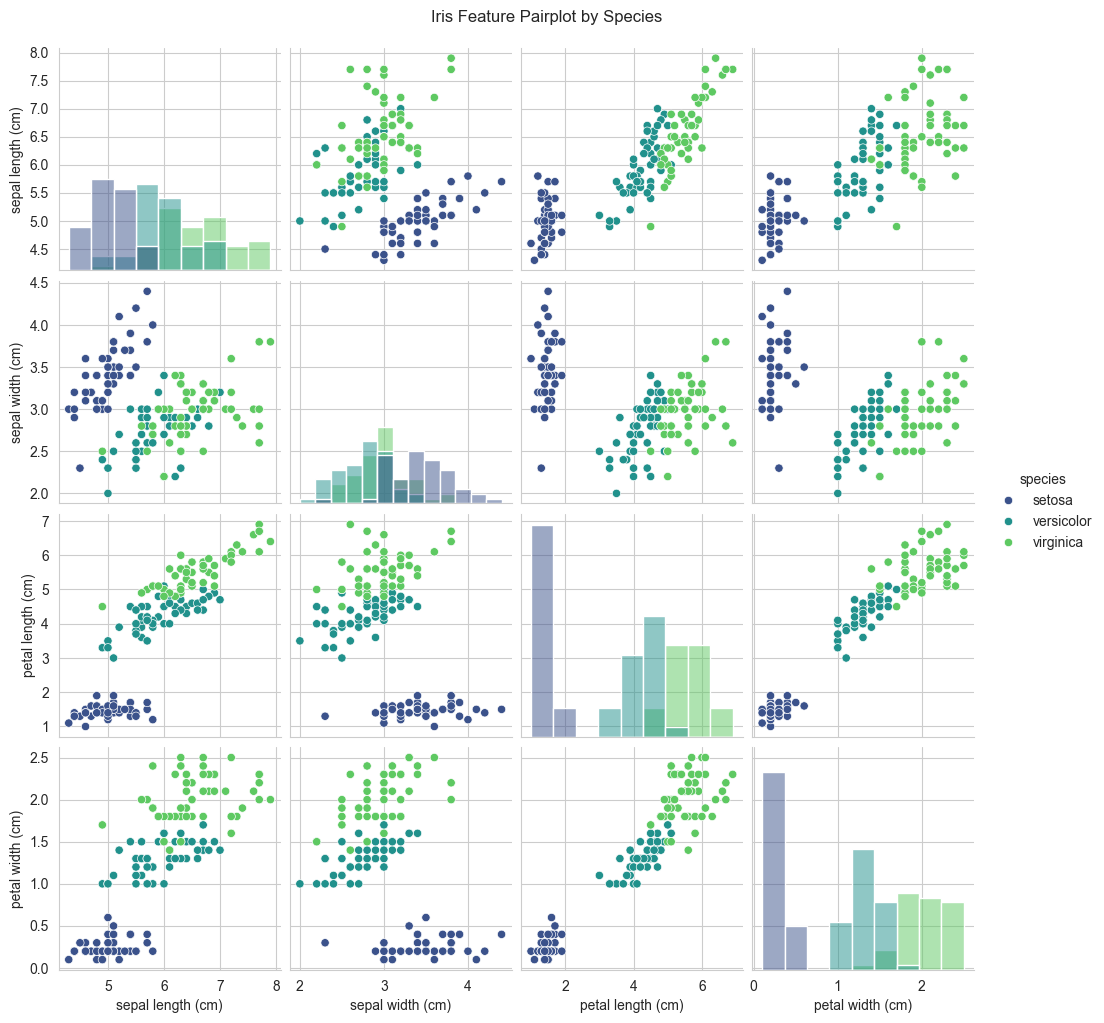

In [5]:
sns.pairplot(df, hue="species", diag_kind="hist", palette="viridis")
plt.suptitle("Iris Feature Pairplot by Species", y=1.02)
plt.show()

**Reading the pairplot:** *Setosa* (purple) is clearly separated from the other two species on
almost every feature pair, especially anything involving petal length or petal width. *Versicolor*
and *Virginica* overlap somewhat but are still mostly separable, particularly on the petal
length/petal width plot.

### 4.2 Box plots — spread of each feature by species

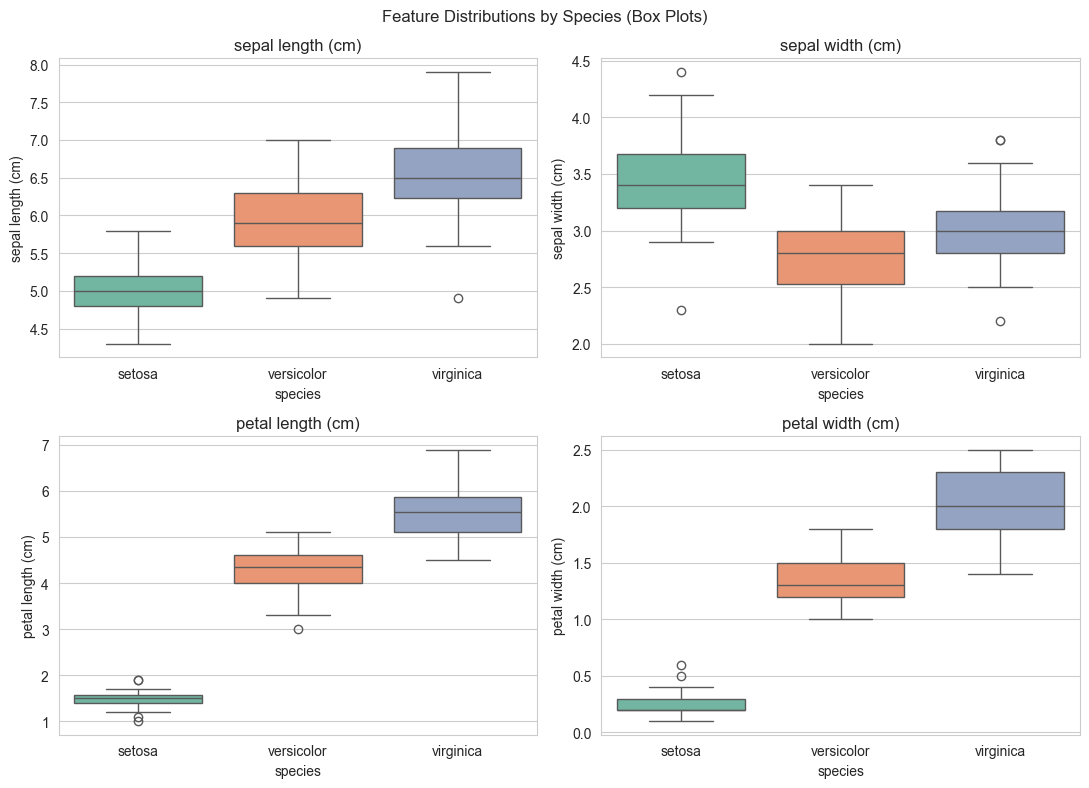

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flatten(), iris.feature_names):
    sns.boxplot(data=df, x="species", y=col, hue="species", palette="Set2", ax=ax, legend=False)
    ax.set_title(col)
fig.suptitle("Feature Distributions by Species (Box Plots)")
fig.tight_layout()
plt.show()

**Reading the box plots:** Petal length and petal width show almost no overlap between
*Setosa* and the other two species, and comparatively little overlap between *Versicolor*
and *Virginica*. Sepal width is the least useful feature — its boxes overlap heavily
across all three species.

### 4.3 Correlation heatmap

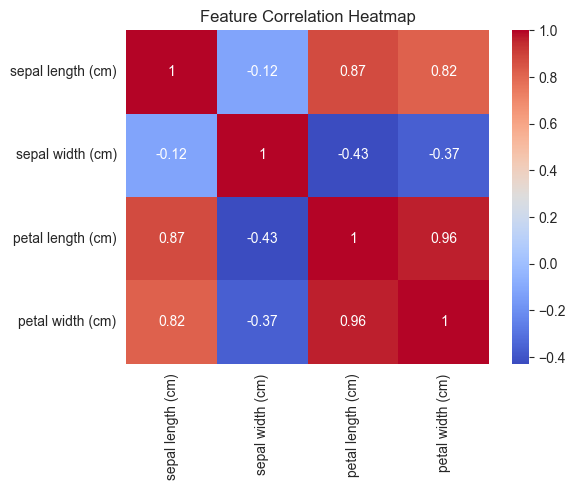

In [7]:
corr = df.drop(columns="species").corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

## 5. Feature Selection Discussion

Based on the EDA above:
- **Petal length** and **petal width** are the most discriminative features — they show the
  cleanest separation between species in both the pairplot and the box plots, and they are
  also strongly correlated with each other (~0.96), meaning they carry consistent, reinforcing
  signal about species identity.
- **Sepal length** is moderately useful.
- **Sepal width** is the weakest predictor — its distributions overlap heavily across all
  three species.

Since the dataset only has 4 features and the models used below (Logistic Regression, KNN,
Decision Tree, Random Forest) all handle a small number of features efficiently, all four
features are kept for training rather than dropping sepal width — but this discussion
explains *why* petal measurements matter most, and it's exactly why a Decision Tree
typically splits on petal length/width first.

## 6. Train/Test Split

An 80/20 split is used, stratified by species so that each class is proportionally
represented in both the training and test sets.

In [8]:
X = df[iris.feature_names]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])

Train size: 120
Test size: 30


## 7. Train Multiple Classifiers

Four classifiers are trained and compared: **Logistic Regression**, **K-Nearest Neighbours**,
**Decision Tree**, and **Random Forest** (two are required by the task; four are trained here
for a more thorough comparison).

In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "K-Nearest Neighbours": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"=== {name} ===")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred))
    print()

=== Logistic Regression ===
Accuracy: 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


=== K-Nearest Neighbours ===
Accuracy: 1.0000
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


=== Decision Tree ===
Accuracy: 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        

## 8. Confusion Matrices

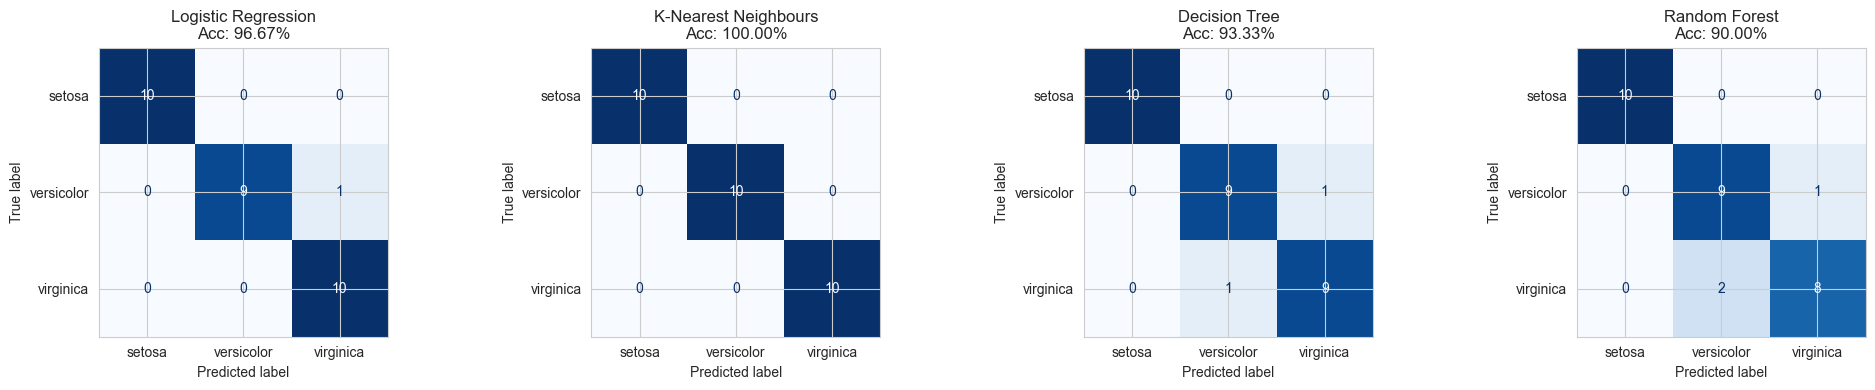

In [10]:
fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4))
for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=iris.target_names)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\nAcc: {accuracy_score(y_test, y_pred):.2%}")
fig.tight_layout()
plt.show()

## 9. Model Comparison and Conclusion

In [11]:
comparison = pd.Series(results).sort_values(ascending=False)
print(comparison)

best_model = comparison.idxmax()
print(f"\nBest performing model: {best_model} (accuracy = {comparison.max():.4f})")

K-Nearest Neighbours    1.000000
Logistic Regression     0.966667
Decision Tree           0.933333
Random Forest           0.900000
dtype: float64

Best performing model: K-Nearest Neighbours (accuracy = 1.0000)


### Conclusion

**K-Nearest Neighbours (KNN, k=5)** was the best-performing model on this test split, achieving
**100% accuracy** with perfect precision, recall, and F1-score across all three species.

**Why KNN works so well here:** the Iris dataset's classes form fairly tight, well-separated
clusters in feature space (as seen in the pairplot), especially once petal length/width are
factored in. KNN classifies a point based on the majority class of its nearest neighbours, so
it thrives exactly on this kind of geometrically well-clustered data. Logistic Regression came
close (96.7%) since the classes are also close to linearly separable. Decision Tree and Random
Forest, while still strong, are slightly more prone to overfitting small quirks in the training
split on a dataset this small (150 rows), which shows up as a couple of misclassifications
between the more similar *Versicolor* and *Virginica* classes.

**Caveat:** With only 30 test samples, a 100% score should be read with some caution — on a
different random split, KNN and Logistic Regression would likely trade places occasionally.
Cross-validation (not required by this task, but a natural next step) would give a more robust
estimate of true generalisation performance.
